# Projeto: sinistralidade rodoviária

| Elemento | Nome | N.º |
|---|---|---|
| 1 | Tomás Miguel | 17 |
| 2 | Bruno | 2 |
| 3 (só num grupo de 3) |  |  |

Dados: `acidentes.csv` (dados de treino, valores fictícios). Escreve em cada secção uma frase a explicar o que fizeste e porquê.

## 1. Planeamento

- Pergunta 1: Que causa tem mais mortos?
- Pergunta 2: Em que mês há mais acidentes?
- Colunas que vou usar: causa, mortos (pergunta 1); mes, acidentes (pergunta 2); ano (para o filtro)
- Filtro (qual?): só o ano mais recente (ano == 2024), para os meses não misturarem dois anos
- Gráfico de barras (de quê?): mortos por causa (categorias: Velocidade, Distração, Álcool, Outra)
- Gráfico de linhas (de quê?): acidentes por mês, de janeiro a dezembro (evolução ao longo do tempo)
- Quem faz o quê:
  - Aula 31: [Elemento 1] lê e limpa os dados; [Elemento 2] faz o filtro. Cada um faz commit do seu.
  - Aula 32: [Elemento 1] faz o groupby e o gráfico de barras; [Elemento 2] faz o gráfico de linhas, a função percentagem() e o teste. Revisão a pares.
  - Aula 33: os dois escrevem as conclusões; [Elemento 2] faz o push final, [Elemento 1] prepara os slides.

## 2. Leitura e limpeza

In [11]:
import pandas as pd

df = pd.read_csv("acidentes.csv")
print(df.shape)

df = df.drop_duplicates()
df = df.dropna(subset=["feridos"])
print(df.shape)

(290, 7)
(285, 7)


## 3. Seleção

Filtra os dados (por exemplo, só um ano ou um distrito).

In [12]:
print(df["ano"].unique())

ano_recente = df["ano"].max()
df_ano = df[df["ano"] == ano_recente]
print(df_ano.shape)

[2023 2024]
(143, 7)


## 4. Agrupamento

Agrupa com groupby e soma.

In [13]:
# Pergunta 1: que causa tem mais mortos?
mortos_por_causa = df.groupby("causa")["mortos"].sum().sort_values(ascending=False)
print(mortos_por_causa)

# Pergunta 2: em que mês há mais acidentes?
acidentes_por_mes = df_ano.groupby("mes")["acidentes"].sum()
print(acidentes_por_mes)
print("Mês com mais acidentes:", acidentes_por_mes.idxmax())
print("Meses na tabela:", len(acidentes_por_mes))

causa
Velocidade    40
Distração     21
Álcool         9
Outra          6
Name: mortos, dtype: int64
mes
1     142
2     134
3     144
4     155
5     151
6     173
7     206
8     203
9     160
10    161
11    150
12    184
Name: acidentes, dtype: int64
Mês com mais acidentes: 7
Meses na tabela: 12


## 5. Gráficos

Um gráfico de barras e um gráfico de linhas, com título e nome dos eixos.

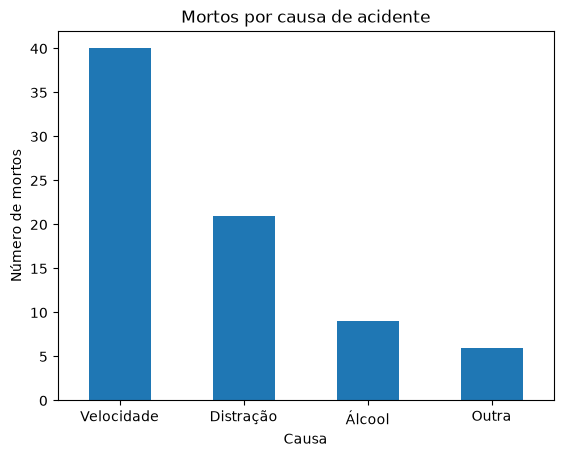

In [14]:
import matplotlib.pyplot as plt

mortos_por_causa.plot(kind="bar")
plt.title("Mortos por causa de acidente")
plt.xlabel("Causa")
plt.ylabel("Número de mortos")
plt.xticks(rotation=0)
plt.show()

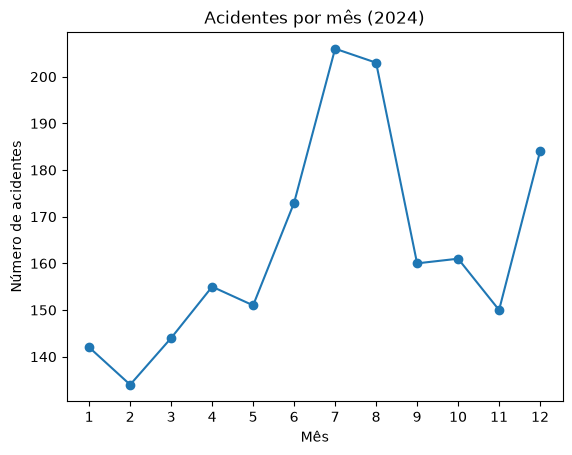

In [15]:
import matplotlib.pyplot as plt

acidentes_por_mes.plot(kind="line", marker="o")
plt.title(f"Acidentes por mês ({ano_recente})")
plt.xlabel("Mês")
plt.ylabel("Número de acidentes")
plt.xticks(range(1, 13))
plt.show()

## 6. Teste
 
Escreve a função num ficheiro `funcoes.py` e o teste em `test_projeto.py`. Corre `pytest` no terminal.

## Extensão: mortos por 100 acidentes, em cada causa

Pergunta nossa: que causa é mais perigosa por acidente? A tabela dá para responder, porque tem acidentes e mortos por causa.

In [16]:
from funcoes import percentagem

por_causa = df.groupby("causa")[["acidentes", "mortos"]].sum()
print(por_causa["acidentes"].min())

por_causa["mortos_por_100"] = [
    percentagem(m, a) for m, a in zip(por_causa["mortos"], por_causa["acidentes"])
]
print(por_causa.sort_values("mortos_por_100", ascending=False))

573
            acidentes  mortos  mortos_por_100
causa                                        
Velocidade       1229      40        3.254679
Distração        1163      21        1.805675
Álcool            573       9        1.570681
Outra             852       6        0.704225


# Um gráfico de dispersão ou um histograma, a partir de df.plot.

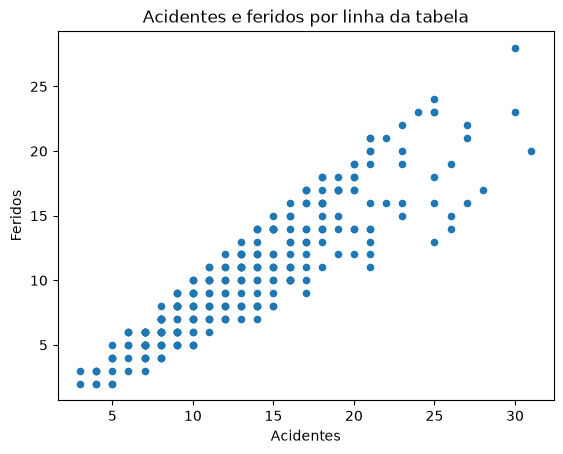

0.9072067496792847


In [17]:
# Dispersão: cada ponto é uma linha da tabela (mês + distrito + causa)
df.plot(kind="scatter", x="acidentes", y="feridos")
plt.title("Acidentes e feridos por linha da tabela")
plt.xlabel("Acidentes")
plt.ylabel("Feridos")
plt.show()

print(df["acidentes"].corr(df["feridos"]))

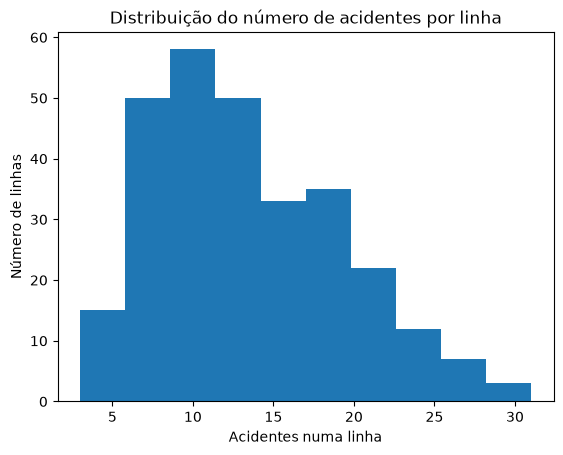

In [18]:
# Histograma: como se distribuem os acidentes por linha
df["acidentes"].plot(kind="hist", bins=10)
plt.title("Distribuição do número de acidentes por linha")
plt.xlabel("Acidentes numa linha")
plt.ylabel("Número de linhas")
plt.show()

# Mais um teste, para outra função do teu projeto.

In [19]:
from funcoes import percentagem, mais_frequente

print(mais_frequente(mortos_por_causa.to_dict()))

Velocidade


## 7. Conclusões

1. A Velocidade é a causa com mais mortos: 40, contra 21 na Distração, 9 no Álcool e 6 em Outra (2023 e 2024 juntos).
2. Em 2024, julho foi o mês com mais acidentes (206), seguido de agosto (203), e fevereiro o mês com menos (134).
3. A Velocidade também é a causa mais perigosa por acidente: 3,25 mortos por 100 acidentes, contra 0,70 em Outra.